In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

import importlib.metadata as md

print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", md.version("tensorflow-datasets"))


TensorFlow version: 2.20.0
TensorFlow Datasets version: 4.9.10


In [ ]:
!python -c "import tensorflow_datasets as tfds; print(tfds.load)"

<function load at 0x7ac040235b20>


In [ ]:
(train_ds, val_ds), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
)
print("Dataset downloaded successfully")


IMG_SIZE = 64          # was 128, about 4x cheaper per image
BATCH_SIZE = 32
TRAIN_SAMPLES = 4000   # full dataset has ~23,000 images
VAL_SAMPLES = 1000
EPOCHS = 5



Dataset downloaded successfully


In [ ]:

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))  # resize
    image = tf.cast(image, tf.float32) / 255.0            # normalize to [0, 1]
    return image, label


train_ds = train_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

# shuffle, batch, prefetch
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
print("Preprocessing completed")



Preprocessing completed


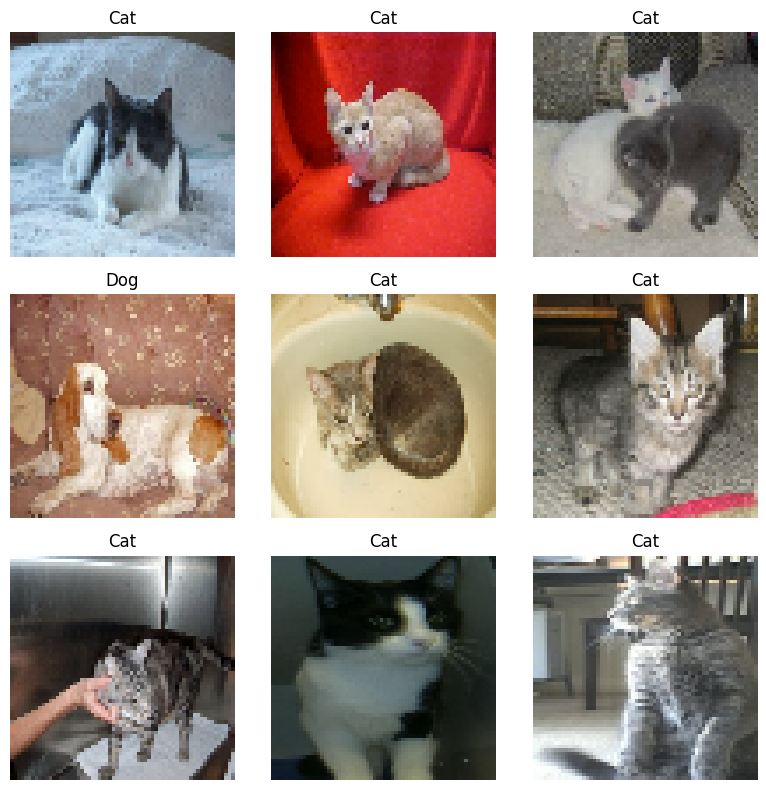

In [ ]:
# %% Display sample images
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title("Cat" if labels[i] == 0 else "Dog")
        plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# %% Create the CNN model
model_a = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),                      # feature maps -> vector
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),                   # reduce overfitting
    tf.keras.layers.Dense(1, activation="sigmoid"), # binary output
])
model_a.summary()

model_a.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# %% Train the CNN
history_a = model_a.fit(train_ds, validation_data=val_ds, epochs=5)

loss, accuracy = model_a.evaluate(val_ds)
print(f"Validation loss: {loss:.4f}")
print(f"Validation accuracy: {accuracy:.4f}")



Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 166s 281ms/step - accuracy: 0.6248 - loss: 0.6385 - val_accuracy: 0.7143 - val_loss: 0.5504
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 165s 282ms/step - accuracy: 0.7413 - loss: 0.5220 - val_accuracy: 0.7794 - val_loss: 0.4776
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 165s 280ms/step - accuracy: 0.7891 - loss: 0.4560 - val_accuracy: 0.7844 - val_loss: 0.4561
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 206s 287ms/step - accuracy: 0.8195 - loss: 0.4046 - val_accuracy: 0.8067 - val_loss: 0.4134
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 164s 281ms/step - accuracy: 0.8430 - loss: 0.3583 - val_accuracy: 0.8308 - val_loss: 0.3778
146/146 ━━━━━━━━━━━━━━━━━━━━ 15s 99ms/step - accuracy: 0.8308 - loss: 0.3778
Validation loss: 0.3778
Validation accuracy: 0.8308


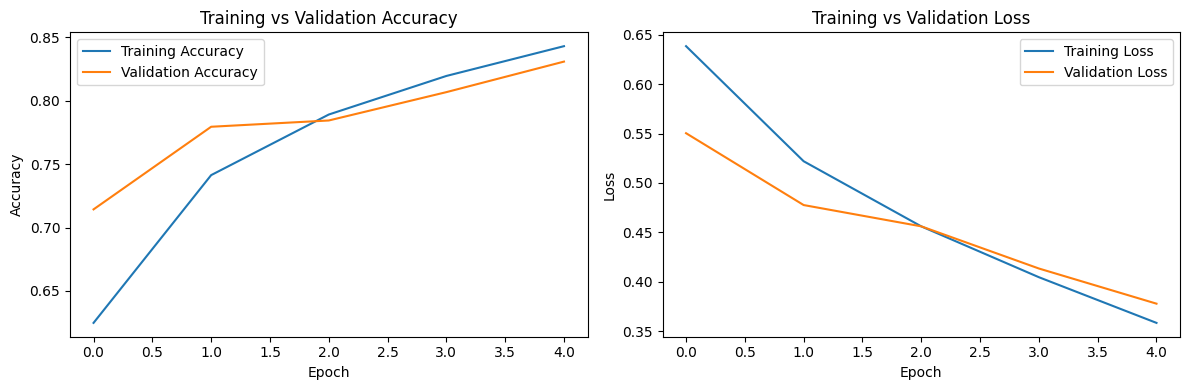

In [ ]:
# %% Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_a.history["accuracy"], label="Training Accuracy")
plt.plot(history_a.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_a.history["loss"], label="Training Loss")
plt.plot(history_a.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()